# Validation of AGB using mainly raster reference datasets

In [2]:
library(aws.s3)
library(tidyverse)
library(sf)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Linking to GEOS 3.12.1, GDAL 3.8.5, PROJ 9.4.0; sf_use_s2() is TRUE



### Plot AGB reference in Siberia - only 39 points - highly spatially autocorrelated

In [33]:
# Or store the names first, then use them
col_names_biomass <- names(plots)[str_detect(names(plots), "biom")]

In [68]:
plots = st_read('/projects/my-public-bucket/databank/extract_from_points/shevtsova_2020_s3_20251112.gpkg') %>%
    as.data.frame() %>% 
    mutate(ref_agbd_total = rowSums(select(., all_of(col_names_biomass)))) %>%
     pivot_longer(
    cols = starts_with("value_agb_"),
    names_to = "variable",
    names_prefix = "value_",  # Removes "value" from the beginning
    values_to = "value"
  ) %>%
    filter(value > -9999) %>%
    mutate(diff_mgha = value - ref_agbd_total/1000)

Reading layer `shevtsova_2020_s3_20251112' from data source 
  `/projects/my-public-bucket/databank/extract_from_points/shevtsova_2020_s3_20251112.gpkg' 
  using driver `GPKG'
Simple feature collection with 39 features and 42 fields
Geometry type: POINT
Dimension:     XY
Bounding box:  xmin: 163.3523 ymin: 67.36703 xmax: 168.7107 ymax: 68.46781
Geodetic CRS:  WGS 84


Coordinate system already present. Adding new coordinate system, which will
replace the existing one.


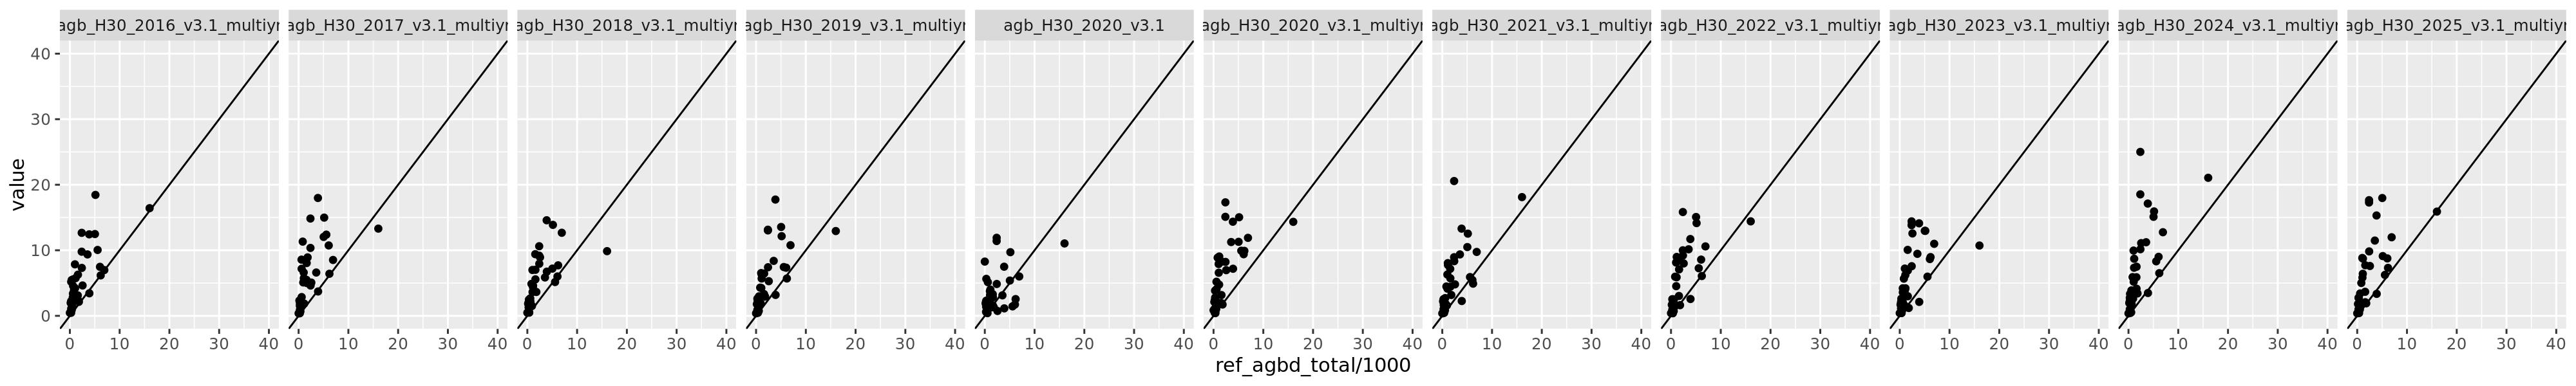

In [59]:
options(repr.plot.width = 20, repr.plot.height = 3, repr.plot.res = 200 , warn = -1 )

ggplot(plots) + 
    geom_abline() +
    geom_point(aes(x=ref_agbd_total/1000, y=value)) +     
    coord_equal() +
    coord_cartesian(ylim=c(0,40), xlim=c(0,40)) +
    facet_wrap(~variable, ncol=11)

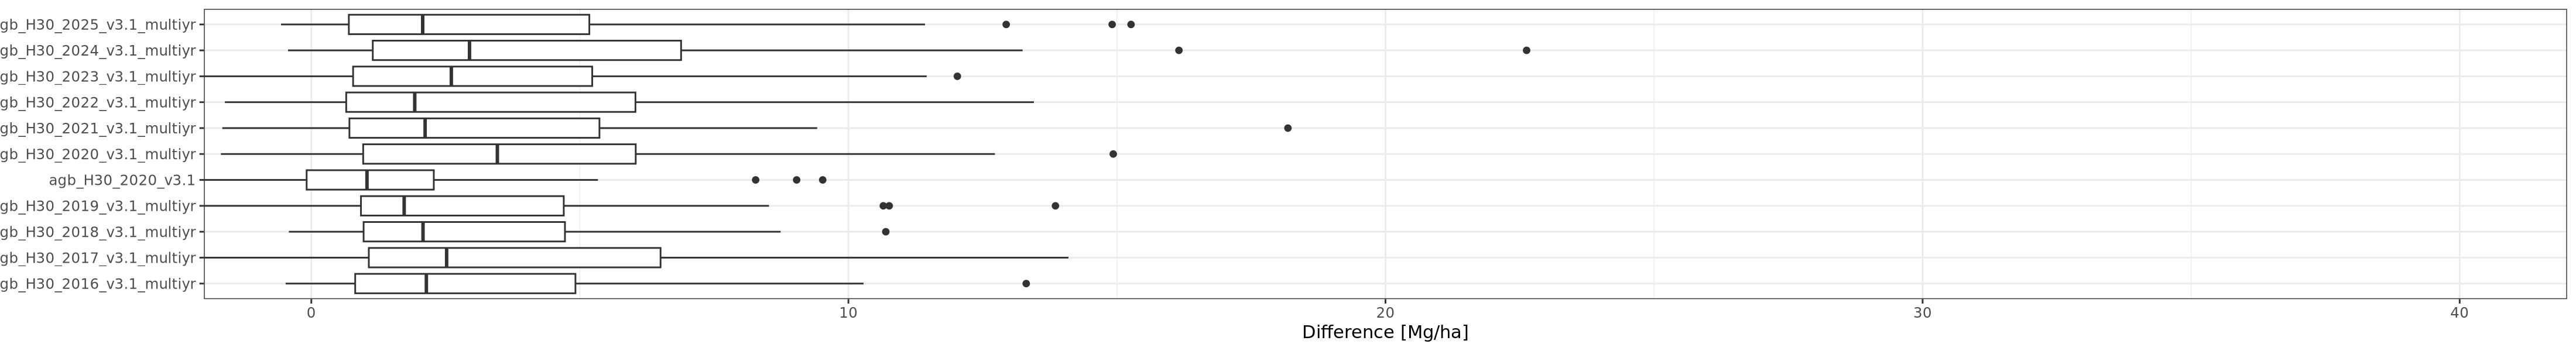

In [76]:
options(repr.plot.width = 22, repr.plot.height = 3, repr.plot.res = 200 , warn = -1 )

ggplot(plots) + 
    geom_boxplot(aes(x = factor(variable), y=diff_mgha)  )  + 
    labs(x=NULL, y= 'Difference [Mg/ha]') +
    coord_flip(ylim=c(0,40)) +
    theme_bw()

### Raster reference

In [6]:
Sys.setenv("AWS_DEFAULT_REGION"="us-west-2") 

In [33]:
objs <- get_bucket(bucket = 'maap-ops-workspace', prefix = 'aliz237/AGB_validation_results/', max = Inf)

df_list = list()
for(obj in objs[1:1]){

    fn = obj$Key
    print(fn)
    
    df = s3read_using(FUN = read.csv, object = obj)

    result = str_split(str_remove(obj$Key, '_all_sites_validation.csv'), '/')[[1]][3]
    result2 = str_split(result, '_')
    
    df$map = str_split(result, '_v')[[1]][1]
    df$version = str_split(result, '_')[[1]][4]
    df$model_type = ifelse(is.na(result2[[1]][5]), 'singleyr', result2[[1]][5])
    df_list[[fn]] = df
    }

[1] "aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv"


In [34]:
dim(df)

[1] 5554756      10

In [6]:
df_val = do.call('rbind', df_list)

In [7]:
head(df_val)

,x,y,lon,lat,pred,ref,site,map,version,model_type
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv.1,1448525,3171226,-147.3406,65.24077,11.150114,5.961319,Bona,AGB_H30_2016,v3.1,multiyr
aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv.2,1448465,3171196,-147.3420,65.24078,14.760878,18.079071,Bona,AGB_H30_2016,v3.1,multiyr
aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv.3,1448495,3171196,-147.3414,65.24066,13.454619,28.419270,Bona,AGB_H30_2016,v3.1,multiyr
aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv.4,1448525,3171196,-147.3409,65.24053,10.216116,15.942097,Bona,AGB_H30_2016,v3.1,multiyr
aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv.5,1448555,3171196,-147.3403,65.24041,9.366086,15.874581,Bona,AGB_H30_2016,v3.1,multiyr
aliz237/AGB_validation_results/AGB_H30_2016_v3.1_multiyr_all_sites_validation.csv.6,1448585,3171196,-147.3397,65.24028,9.444451,18.746346,Bona,AGB_H30_2016,v3.1,multiyr


In [8]:
write.csv(df_val, file = '/projects/my-public-bucket/databank/boreal_agb_validation/all_sites_validation_various_versions.csv', row.names = FALSE)

In [7]:
df_val = read.csv('/projects/my-public-bucket/databank/boreal_agb_validation/all_sites_validation_various_versions.csv')

In [140]:
breaks <- seq(0, 300, 10)
labels <- paste(breaks[-length(breaks)], breaks[-1], sep = "-")

df_val = df_val %>% 
    mutate(
        diff = pred-ref,
        ref_class = cut(ref, 
                            breaks = breaks,
                            labels = labels,
                            include.lowest = TRUE)
      )

In [36]:
names(df_val)

[1] "x"          "y"          "lon"        "lat"        "pred"      
 [6] "ref"        "site"       "map"        "version"    "model_type"

In [8]:
levels(factor(df_val$site))

[1] "Bona"          "DeltaJunction" "Healy"         "norway1"      
[5] "norway2"       "norway3"       "norway4"       "norway5"      
[9] "norway6"

In [26]:
levels(factor(df_val$map))

[1] "AGB_H30_2016" "AGB_H30_2017" "AGB_H30_2018" "AGB_H30_2019" "AGB_H30_2020"
 [6] "AGB_H30_2021" "AGB_H30_2022" "AGB_H30_2023" "AGB_H30_2024" "AGB_H30_2025"

In [12]:
library(viridis)

Loading required package: viridisLite



In [42]:
#source('/projects/code/3dsi/plot_functions.R')

lm_eqn_boreal_agb = function(df){
  y = df[, 'pred']
  x = df[,'ref']
  m = lm(y ~ x, df);
  
  eq <- substitute(italic(y) == a + b %.% italic(x)*","~~italic(r)^2~"="~r2, 
                   list(a = format(coef(m)[1], digits = 2), 
                        b = format(coef(m)[2], digits = 2), 
                        r2 = format(summary(m)$r.squared, digits = 3)))
  int = round(coef(m)[1], digits = 2)
  slope = round(coef(m)[2], digits = 2)
  # https://stackoverflow.com/questions/43123462/how-to-obtain-rmse-out-of-lm-result
  
  rss   <- c(crossprod(m$residuals))
  mse   <- rss / length(m$residuals)

  rmsd <- format(sqrt(mean((y-x)*(y-x))), dig=2)
  
  rmse  <- round(sqrt(mse),dig=2)
  sig2  <- round(rss / m$df.residual, dig=2) # Pearson estimated residual variance (as returned by summary.lm):
  n     <- nobs(m)
  paste('model n obs: ',n) 
  r2    <- round(summary(m)$r.squared, dig = 2)
  mae   <- round(mean(abs(m$residuals)), dig = 2)
  mape  <- round(mean(abs((m$residuals)/y))*100, dig=2)  #https://stats.stackexchange.com/questions/299712/what-are-the-shortcomings-of-the-mean-absolute-percentage-error-mape
  rrmse <- round(rmse / mean(x, na.rm = TRUE), dig=2) #https://www.rdocumentation.org/packages/ehaGoF/versions/0.1.1/topics/Goodness%20of%20fit%20-%20Relative%20Root%20Mean%20Square%20Error 
  
  #return(as.character(as.expression(eq)))
  #return(data.frame(cbind(int, slope, r2, rmse, sig2, n, mae, mape)))
  
  model_predictions = as.data.frame(cbind(df, data.frame("y_pred" = stats::predict(m))))
  model_stats = data.frame(cbind(int, slope, r2, rmsd, rmse, sig2, n, mae, mape, rrmse
                                #, as.character(as.expression(eq))
                                ) ) %>% mutate_if(is.character,as.numeric) 
  #return(list(model_stats, model_predictions))
    
  return(model_stats)
}

In [17]:
theme_hex = list(
                geom_hex(),
                scale_fill_viridis(trans='log10', option='plasma'),
                geom_abline(),
                geom_smooth(method='lm', formula= y ~  x),
                coord_equal(),
                theme_bw(),
                labs(x = 'Reference forest AGBD', y = 'Predicted forest AGBD\n(remote sensing)'),
                theme(
                    text = element_text(size=16),
                    strip.text = element_text(size=10),
                    axis.title = element_text(size=22)
                    )
    )

In [83]:
names(df_val)

[1] "x"          "y"          "lon"        "lat"        "pred"      
 [6] "ref"        "site"       "map"        "version"    "model_type"

In [84]:
df_eq <- plyr::ddply(df_val %>% dplyr::select(!c('x','y','lon','lat')) , .variables = c('site', 'map', 'version', 'model_type'), .fun = c("lm_eqn_boreal_agb") )

In [85]:
sum(df_eq$n)

[1] 66656838

In [86]:
tail(df_eq)

,site,map,version,model_type,int,slope,r2,rmsd,rmse,sig2,n,mae,mape,rrmse
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
103,norway6,AGB_H30_2020,v3.2,singleyr,2.82,0.13,0.10,11,3.24,10.53,284788,2.44,92.77,0.25
104,norway6,AGB_H30_2021,v3.1,multiyr,7.11,0.20,0.05,10,7.03,49.43,284795,4.99,80.03,0.55
105,norway6,AGB_H30_2022,v3.1,multiyr,10.39,0.15,0.01,12,9.74,94.83,284782,7.07,94.72,0.76
106,norway6,AGB_H30_2023,v3.1,multiyr,10.38,0.13,0.01,12,9.32,86.92,284795,6.71,92.84,0.73
107,norway6,AGB_H30_2024,v3.1,multiyr,7.24,0.09,0.02,10,5.52,30.47,284795,3.95,59.75,0.43
108,norway6,AGB_H30_2025,v3.1,multiyr,8.84,0.17,0.03,11,8.12,65.98,284785,5.76,84.26,0.63


In [91]:
SITE_LIST = levels(factor(df_val$site)) #c('Healy','Bona')
length(SITE_LIST)

[1] 9

# Looking at year 2020 maps across versions and model type (single or multiyr)  

## + These results arent very different - suggesting at these sites at the pixel level the difference doesnt seem significant.  
## + Not quantified is the effect of the multi-yr model on tile-by-tile model and spatial consistency - they have a larger pool of more consistently distributed ICESat-2 observations

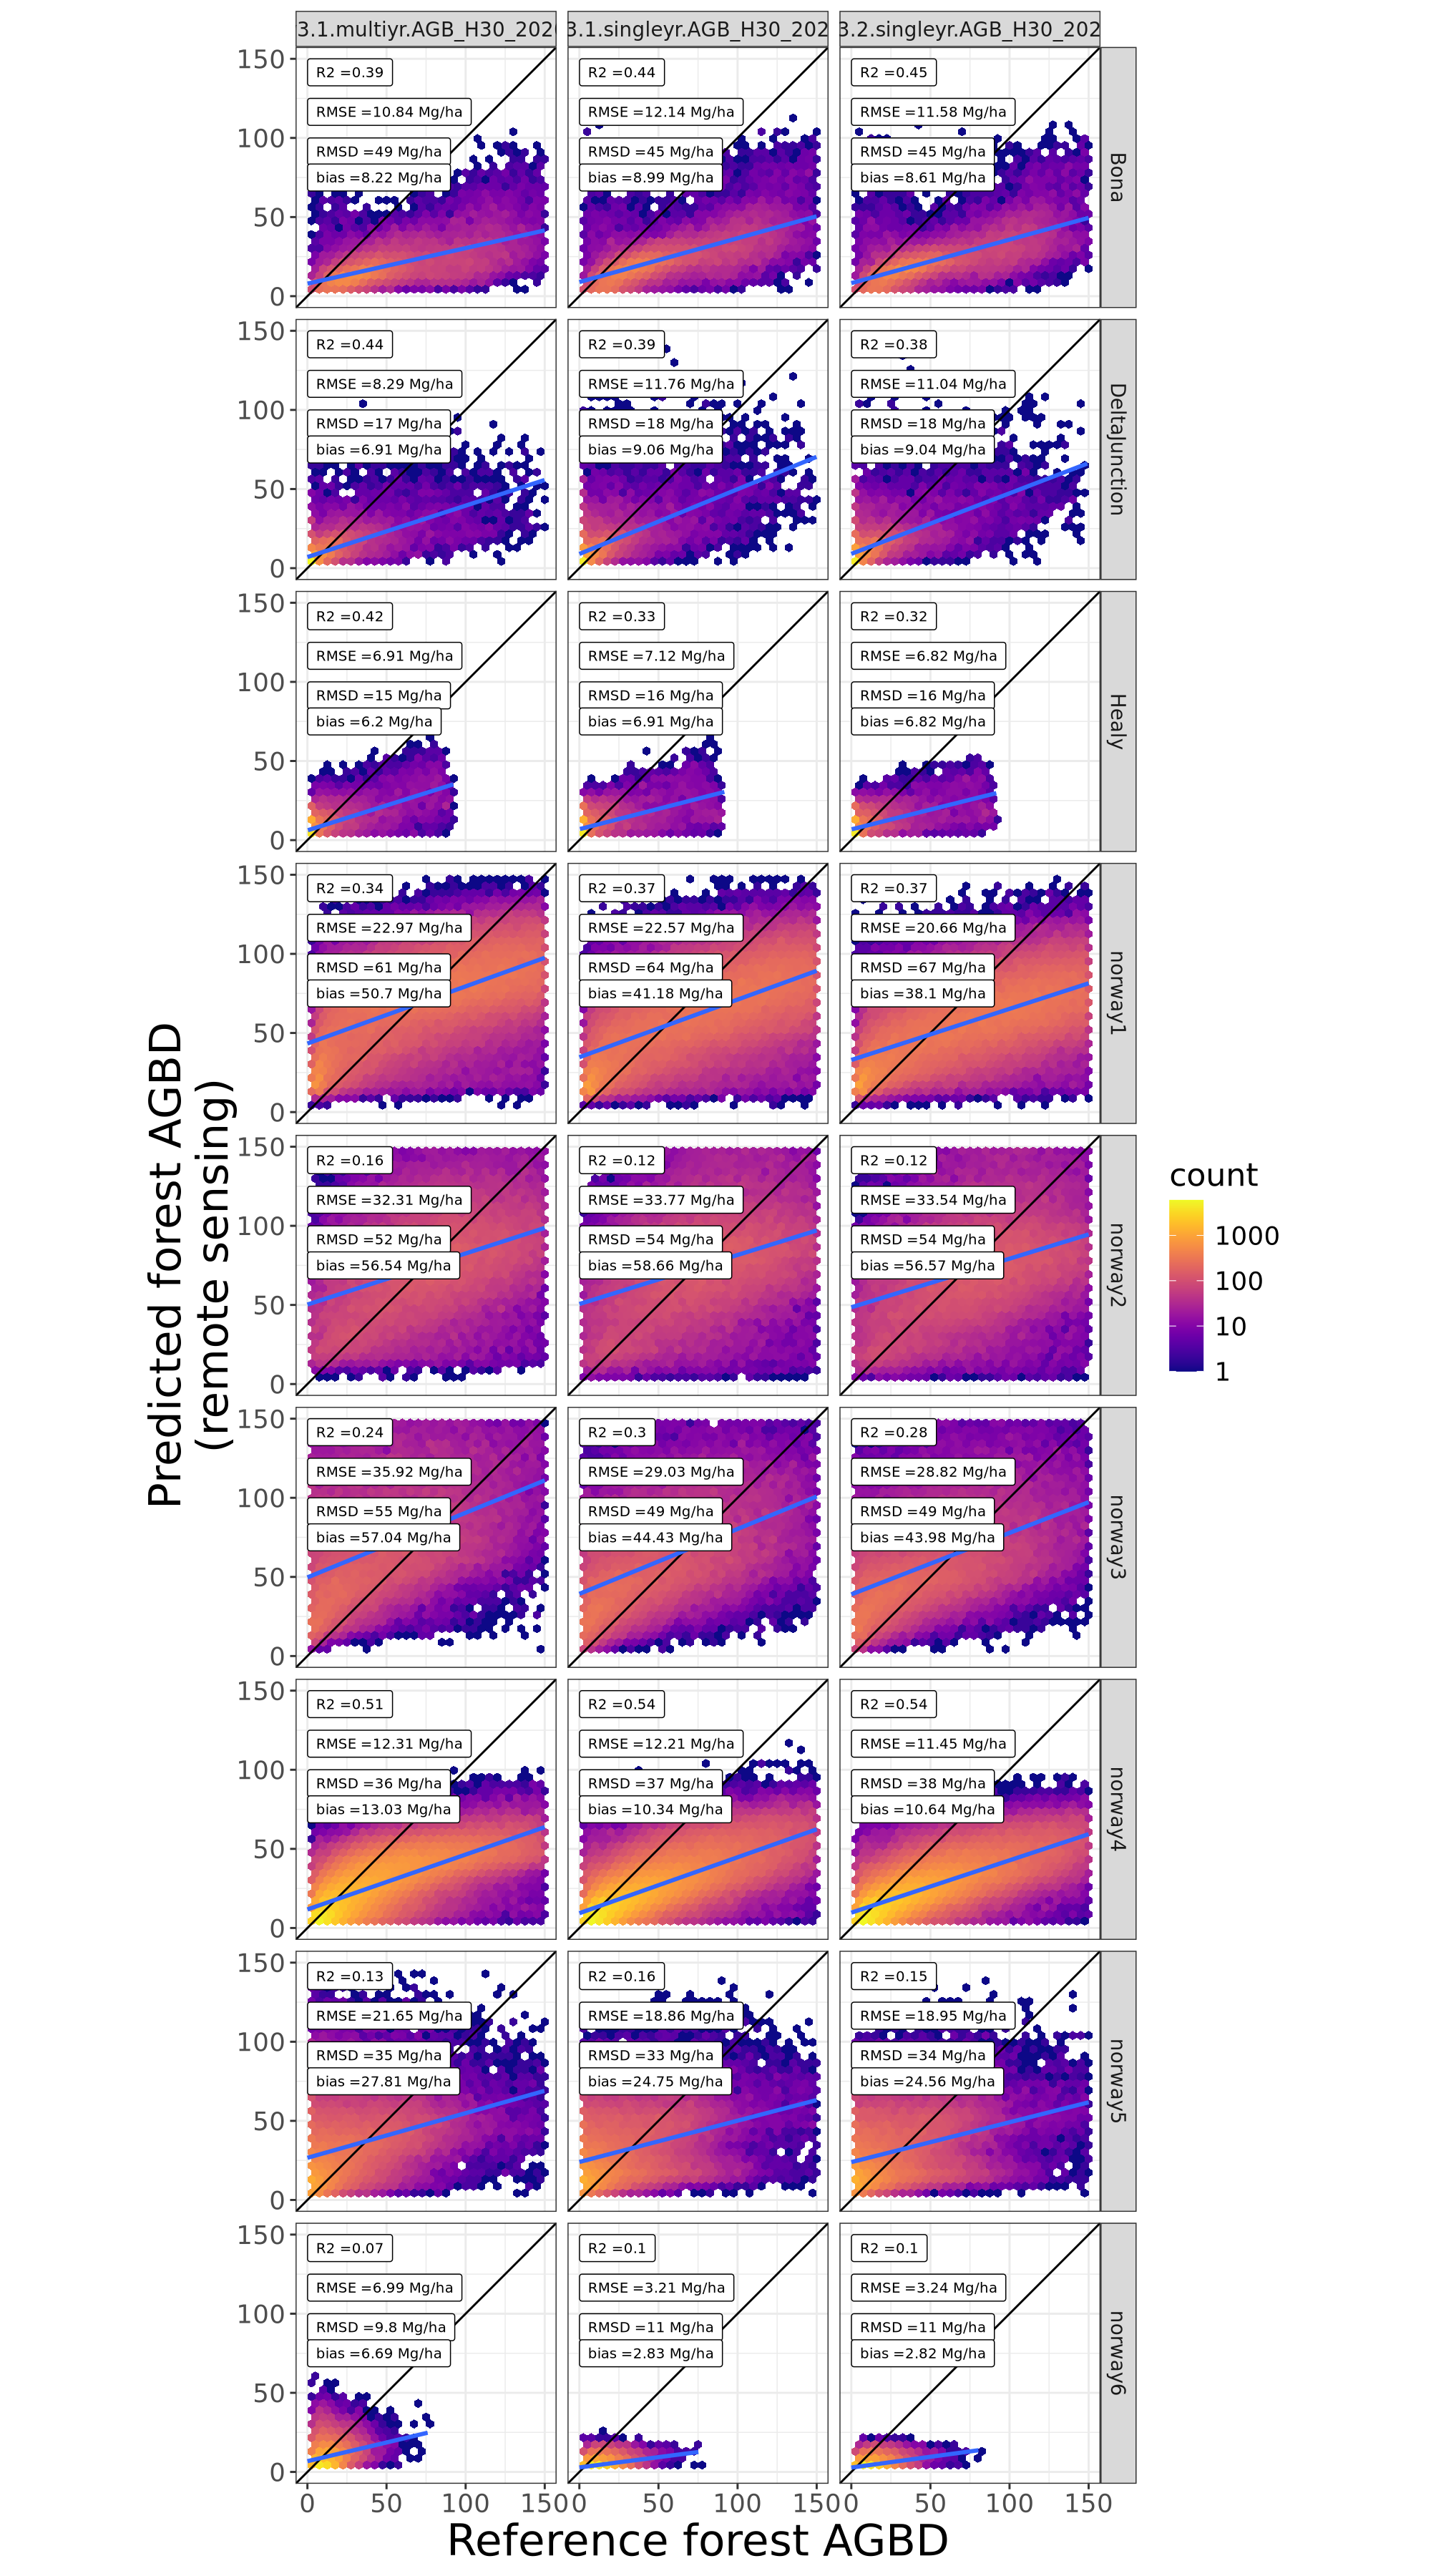

In [165]:
options(repr.plot.width = 10, repr.plot.height = 2 * length(SITE_LIST), repr.plot.res = 200 , warn = -1 )

IDVARS = c('pred','ref')

label_text_sz = 2.5
maxagb = 150
agb_interval = 25

df_eq_sub_2020 = df_eq %>% filter(site %in% SITE_LIST) %>% filter(map == 'AGB_H30_2020')

ggplot(
    sample_frac(df_val %>% filter(site %in% SITE_LIST) %>% filter(map == 'AGB_H30_2020'), 0.1)
    , aes(y=pred, x=ref, group=map)
        ) + 
        theme_hex +
        lims(y=c(0,maxagb), x=c(0,maxagb)) +
        list(        
                geom_label(data=df_eq_sub_2020, mapping=aes(x = 0.1, y = maxagb+(1*agb_interval),label=paste0("n =", n, sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub_2020, mapping=aes(x = 0.1, y = maxagb,label=paste("R2 =", r2, sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub_2020, mapping=aes(x = 0.1, y = maxagb-(1*agb_interval),label=paste("RMSE =", rmse, " Mg/ha", sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub_2020, mapping=aes(x = 0.1, y = maxagb-(2*agb_interval),label=paste("RMSD =", rmsd, " Mg/ha", sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub_2020, mapping=aes(x = 0.1, y = maxagb-(3*agb_interval),label=paste("bias =", int, " Mg/ha", sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines"))
                 ) +
        facet_grid(site~interaction(version, model_type, map))

### 

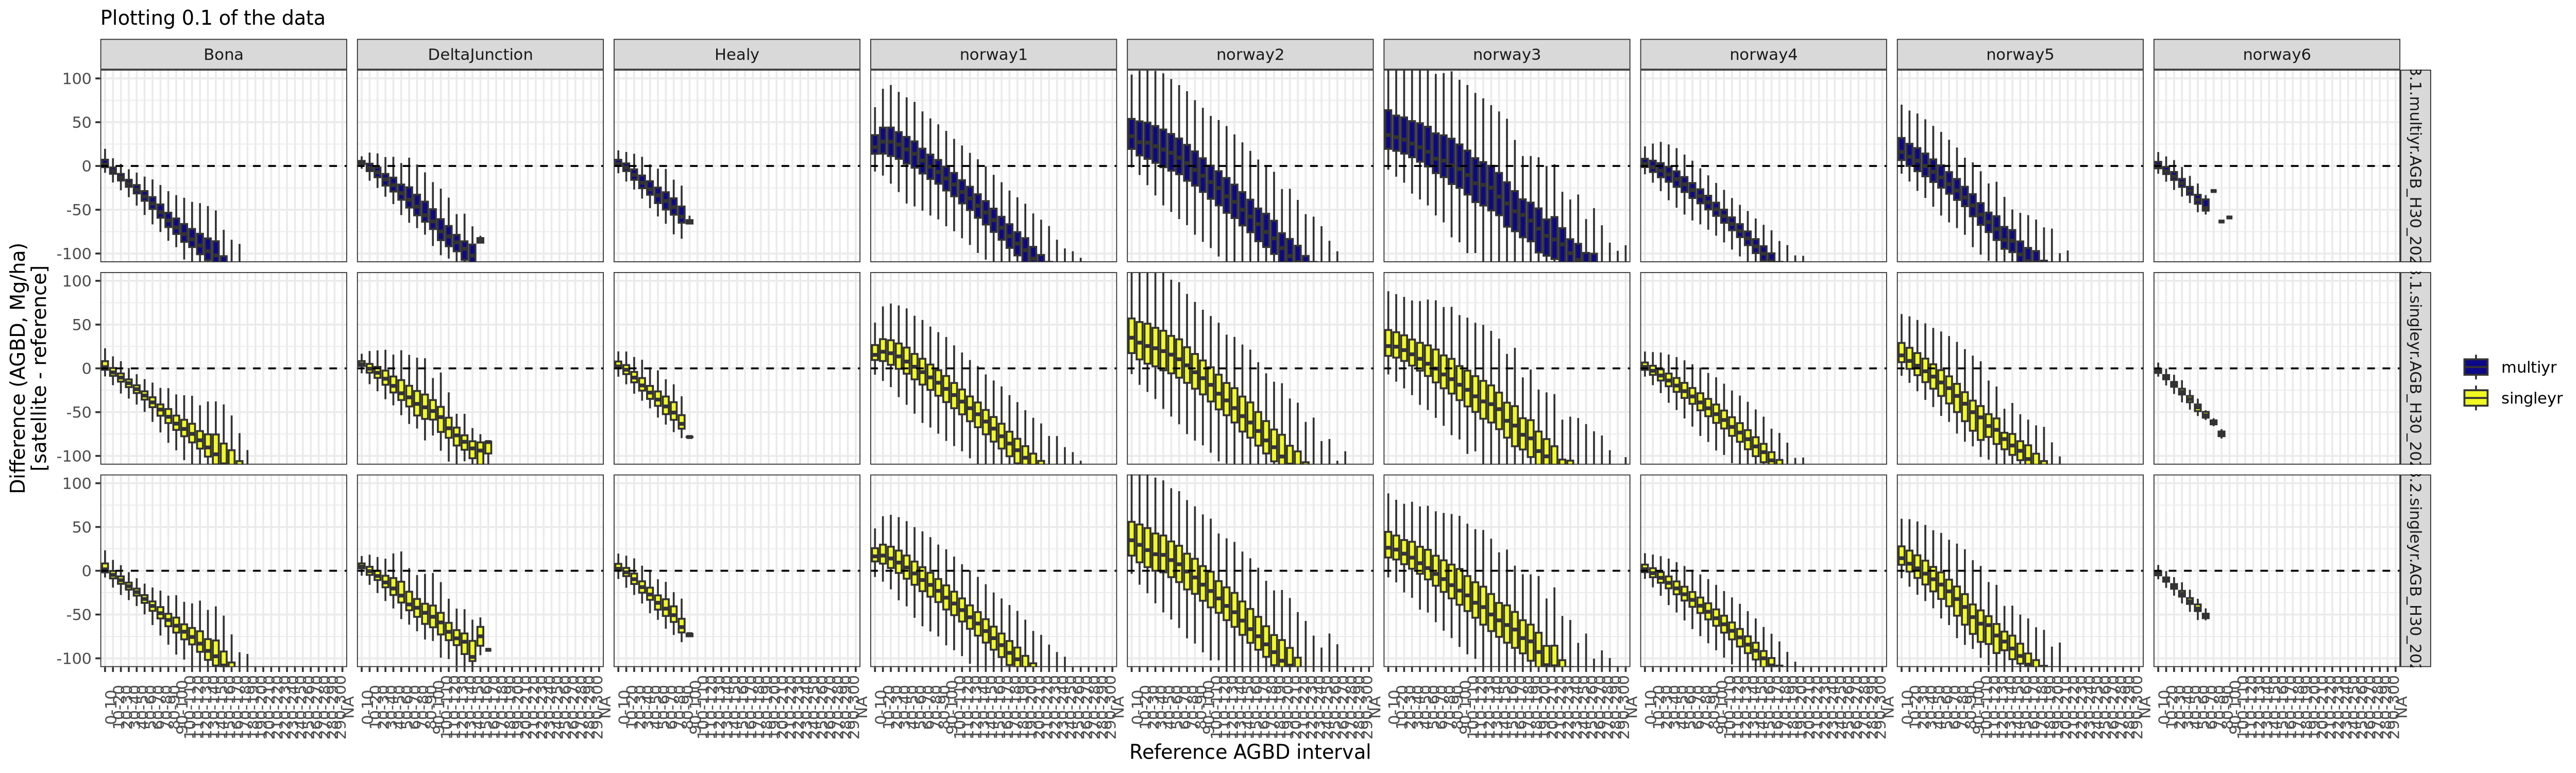

In [166]:
options(repr.plot.width = 20, repr.plot.height = 6, repr.plot.res = 250 , warn = -1 )

IDVARS = c('pred','ref')

label_text_sz = 2.5

agb_interval = 25
FRAC = 0.1

df_eq_sub_2020 = df_eq %>% filter(site %in% SITE_LIST) %>% filter(map == 'AGB_H30_2020')

ggplot(
    sample_frac(df_val %>% filter(site %in% SITE_LIST) %>% filter(map == 'AGB_H30_2020'), FRAC)
    , aes(y=diff, x=ref_class)
        ) + 
                geom_boxplot(aes(fill=model_type), outlier.size=-1) +
                geom_hline(aes(yintercept=0), linetype='dashed') +
                geom_vline(aes(xintercept=125), linetype='dashed') +
            
                #scale_fill_viridis_d(option='plasma', name='Years difference\n[satellite-field]', guide=FALSE) +
                #scale_fill_viridis_c(option='plasma', name='Year of plot obs.') +
                scale_fill_viridis_d(option='plasma', name=''
                                     #, limits = c(1990, 2025)
                                    ) +
                coord_cartesian(ylim=c(-100,100), ) +
                labs(y='Difference (AGBD, Mg/ha)\n[satellite - reference]', x='Reference AGBD interval', subtitle=paste0('Plotting ',FRAC,' of the data'))+
                theme_bw() + theme(axis.text.x = element_text(angle=90)) +
        facet_grid(interaction(version, model_type, map)~site)

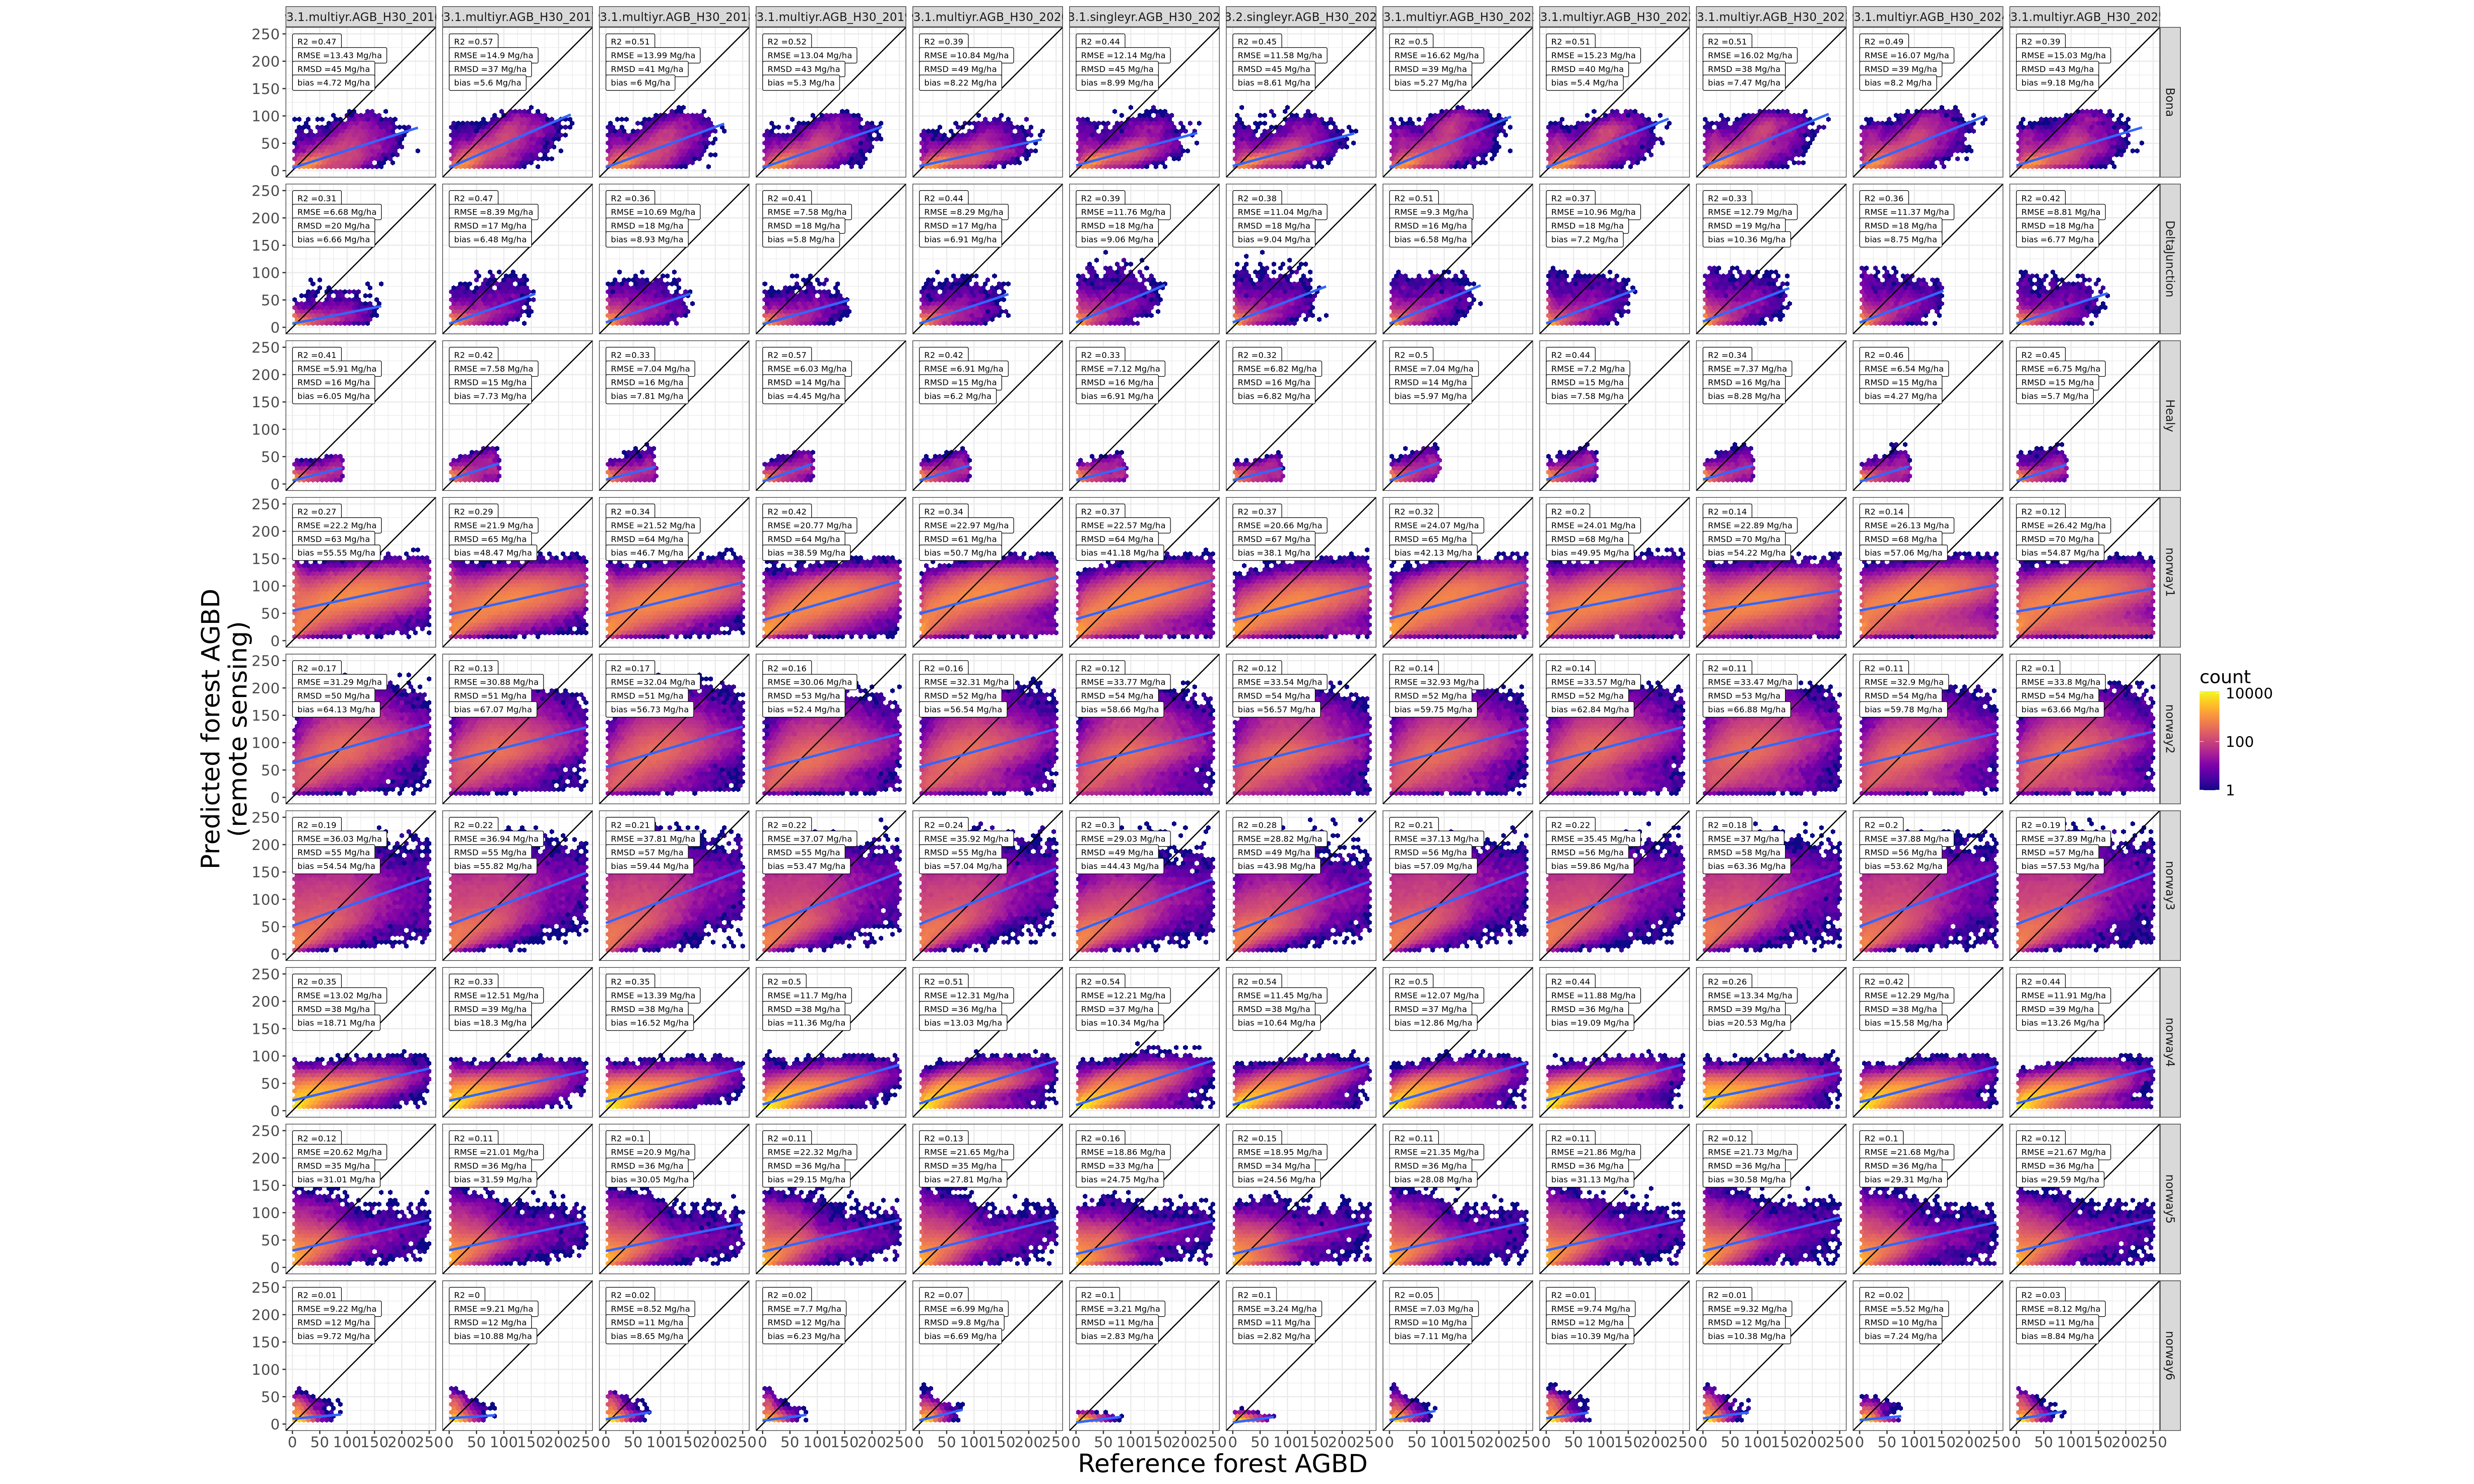

In [135]:
options(repr.plot.width = 30, repr.plot.height = 2 * length(SITE_LIST), repr.plot.res = 200 , warn = -1 )

IDVARS = c('pred','ref')

label_text_sz = 2.5
maxagb = 250
agb_interval = 25

df_eq_sub = df_eq %>% filter(site %in% SITE_LIST)

ggplot(
    sample_frac(df_val %>% filter(site %in% SITE_LIST), 0.1)
    , aes(y=pred, x=ref, group=map)
        ) + 
        theme_hex +
        lims(y=c(0,maxagb), x=c(0,maxagb)) +
        list(        
                geom_label(data=df_eq_sub, mapping=aes(x = 0.1, y = maxagb+(1*agb_interval),label=paste0("n =", n, sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub, mapping=aes(x = 0.1, y = maxagb,label=paste("R2 =", r2, sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub, mapping=aes(x = 0.1, y = maxagb-(1*agb_interval),label=paste("RMSE =", rmse, " Mg/ha", sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub, mapping=aes(x = 0.1, y = maxagb-(2*agb_interval),label=paste("RMSD =", rmsd, " Mg/ha", sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
                geom_label(data=df_eq_sub, mapping=aes(x = 0.1, y = maxagb-(3*agb_interval),label=paste("bias =", int, " Mg/ha", sep='')), parse = FALSE, 
                           hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines"))
                 ) +
        facet_grid(site~interaction(version, model_type, map))

## Linear model results by groups for a single remote sensing dataset

In [100]:
df_eq_m = reshape2::melt(df_eq, id_vars=c('site','map','version','model_type'))

Using site, map, version, model_type as id variables



In [101]:
head(df_eq_m)

,site,map,version,model_type,variable,value
,<chr>,<chr>,<chr>,<chr>,<fct>,<dbl>
1,Bona,AGB_H30_2016,v3.1,multiyr,int,4.72
2,Bona,AGB_H30_2017,v3.1,multiyr,int,5.60
3,Bona,AGB_H30_2018,v3.1,multiyr,int,6.00
4,Bona,AGB_H30_2019,v3.1,multiyr,int,5.30
5,Bona,AGB_H30_2020,v3.1,multiyr,int,8.22
6,Bona,AGB_H30_2020,v3.1,singleyr,int,8.99


#### These boxplots dont shine any light on whether the multi-yr or single-yr is more useful.

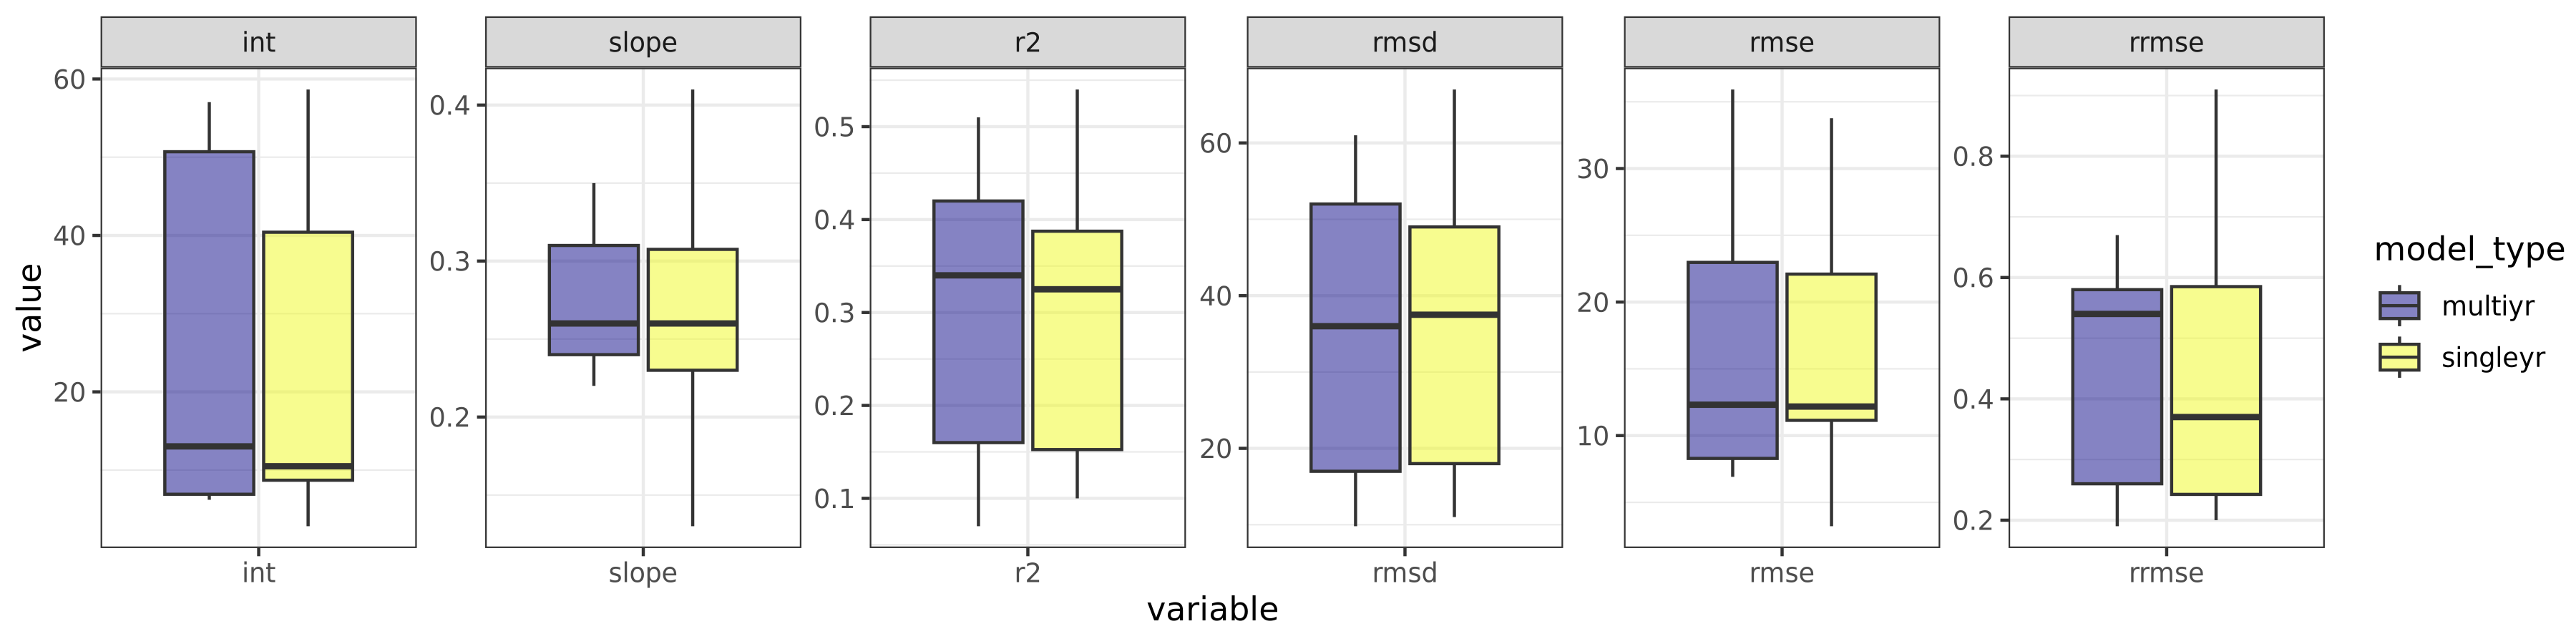

In [125]:
options(repr.plot.width = 12, repr.plot.height = 3, repr.plot.res = 300)

ggplot(df_eq_m %>% 
       filter(variable != 'n') %>%
       filter(str_detect(map, "H30_2020"))%>%
        #filter(str_detect(MAP_VERSION, "v3.0")) #%>%
        filter(!str_detect(variable, "ma")) %>%
        filter(!str_detect(variable, "sig2"))
      ) +
    #geom_point(aes(x=variable, y=value, color=interaction(map, version, model_type)), size=3, shape=19, alpha=0.5) +
    geom_boxplot(aes(x=variable, y=value, fill=model_type), alpha=0.5) +
    #scale_color_brewer(palette='plasma', direction=1) +
    scale_fill_viridis_d(option = 'plasma', direction=1) +
    facet_wrap(.~variable
               , scales='free'
               , ncol=9) +
    theme_bw()

In [ ]:
options(repr.plot.width = 16, repr.plot.height = 8)

df_eq <- plyr::ddply(val_plots_m_final %>% 
                     select(all_of(IDVARS), value, variable, ref_ht, year, group_name, region, diff_yr, continent )
                     , .(variable), c("lm_eqn_boreal_ht") )

htmax = 40
label_text_sz = 4

ggplot(val_plots_m_final, aes( x=ref_ht, y=value)) +
    theme_hex +
    list(        
        geom_label(data=df_eq, mapping=aes(x = 0.1, y = htmax+5,label=paste("n =", n, sep='')), parse = FALSE, 
                   hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
        geom_label(data=df_eq, mapping=aes(x = 0.1, y = htmax,label=paste("R2 =", r2, sep='')), parse = FALSE, 
                   hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
        geom_label(data=df_eq, mapping=aes(x = 0.1, y = htmax-5,label=paste("RMSE =", rmse, " m", sep='')), parse = FALSE, 
                   hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines")),
        geom_label(data=df_eq, mapping=aes(x = 0.1, y = htmax-10,label=paste("bias =", int, " m", sep='')), parse = FALSE, 
                   hjust="inward", vjust="inward", size=label_text_sz, color = "black", fill="white", label.padding=unit(0.5,"lines"))
         ) +
    facet_wrap(.~variable, ncol=6)

In [10]:
options(repr.plot.width = 20, repr.plot.height = 4, repr.plot.res = 200 , warn = -1 )

for(site in levels(factor(df_val$site))){
    
    p_site = ggplot(sample_frac(df_val %>% filter(site == site), 0.0001), aes(y=pred, x=ref, group=map)) + 
        geom_bin2d() +
        scale_fill_viridis_b(trans='log10') +
        coord_equal() +
    lims(y=c(0,250), x=c(0,250))
        geom_abline() +
        facet_grid(version~interaction(model_type, map)) +
        theme_bw()
    
    print(p_site)
    }